# Autocodificador variacional (VAE) con espacio latente de dos dimensiones

Un autocodificador comprime cada imagen en un vector pequeño (el *código latente*) y luego intenta reconstruirla a partir de él. Aunque su decodificador puede convertir cualquier punto del espacio latente en una imagen, el entrenamiento solo le exige reconstruir bien: nada garantiza que el espacio latente tenga una forma conocida ni que esté libre de huecos. En consecuencia, un punto elegido al azar suele producir una imagen sin sentido, y el modelo no sirve para generar datos nuevos.

El autocodificador variacional (Kingma y Welling, 2014) resuelve este problema. En lugar de asignar a cada imagen un punto fijo, el codificador produce una **distribución** sobre el espacio latente, y la función de pérdida obliga a que estas distribuciones se parezcan a una normal estándar. El resultado es un espacio latente continuo y organizado, del que se puede muestrear para generar imágenes nuevas.

En esta libreta se usa un VAE convolucional ya entrenado sobre MNIST, con un espacio latente de solo dos dimensiones para poder visualizarlo directamente. Al final se entrena un autocodificador determinístico con la misma arquitectura para comparar ambos espacios latentes.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from scipy.stats import norm
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

torch.manual_seed(0)
np.random.seed(0)
dispositivo = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Dispositivo:", dispositivo)

Dispositivo: cpu


## Datos

Se usan las imágenes de MNIST con valores de píxel en el intervalo $[0, 1]$. Los pesos del modelo ya están entrenados, así que el conjunto de entrenamiento solo se utiliza en la última sección, para entrenar el autocodificador determinístico de comparación.

In [2]:
transformacion = transforms.ToTensor()
datos_entrenamiento = datasets.MNIST("datos", train=True, download=True, transform=transformacion)
datos_prueba = datasets.MNIST("datos", train=False, download=True, transform=transformacion)

cargador_entrenamiento = DataLoader(datos_entrenamiento, batch_size=128, shuffle=True)
cargador_prueba = DataLoader(datos_prueba, batch_size=512, shuffle=False)
print(len(datos_entrenamiento), "imágenes de entrenamiento |", len(datos_prueba), "imágenes de prueba")

60000 imágenes de entrenamiento | 10000 imágenes de prueba


## Arquitectura

El **codificador** reduce la imagen de 28 × 28 a un mapa de 128 × 7 × 7 mediante dos convoluciones con paso 2. A partir de él, dos capas densas producen los parámetros de una distribución normal en el espacio latente: la media $\mu$ y el logaritmo de la varianza $\log \sigma^2$.

El **decodificador** realiza el camino inverso: una capa densa lleva el código latente de vuelta a 128 × 7 × 7 y dos convoluciones transpuestas reconstruyen la imagen de 28 × 28. La sigmoide final deja los píxeles en $[0, 1]$.

Entre ambos se aplica el **truco de reparametrización**. Muestrear $z \sim \mathcal{N}(\mu, \sigma^2)$ directamente impediría propagar gradientes hacia el codificador, porque el muestreo no es una operación derivable. En su lugar se muestrea $\varepsilon \sim \mathcal{N}(0, 1)$ y se calcula $z = \mu + \sigma \cdot \varepsilon$: el azar queda aislado en $\varepsilon$, y $\mu$ y $\sigma$ pueden ajustarse por descenso de gradiente.

In [3]:
DIM_LATENTE = 2


class Codificador(nn.Module):
    def __init__(self, dim_latente=DIM_LATENTE):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 64, kernel_size=4, stride=2, padding=1)    # 28x28 -> 14x14
        self.conv2 = nn.Conv2d(64, 128, kernel_size=4, stride=2, padding=1)  # 14x14 -> 7x7
        self.fc_mu = nn.Linear(128 * 7 * 7, dim_latente)
        self.fc_logvar = nn.Linear(128 * 7 * 7, dim_latente)
        self.activation = nn.ReLU()

    def forward(self, x):
        h = self.activation(self.conv1(x))
        h = self.activation(self.conv2(h))
        h = h.flatten(start_dim=1)
        return self.fc_mu(h), self.fc_logvar(h)


class Decodificador(nn.Module):
    def __init__(self, dim_latente=DIM_LATENTE):
        super().__init__()
        self.fc = nn.Linear(dim_latente, 128 * 7 * 7)
        self.conv2 = nn.ConvTranspose2d(128, 64, kernel_size=4, stride=2, padding=1)  # 7x7 -> 14x14
        self.conv1 = nn.ConvTranspose2d(64, 1, kernel_size=4, stride=2, padding=1)    # 14x14 -> 28x28
        self.activation = nn.ReLU()

    def forward(self, z):
        h = self.fc(z).view(-1, 128, 7, 7)
        h = self.activation(self.conv2(h))
        return torch.sigmoid(self.conv1(h))


class VAE(nn.Module):
    def __init__(self, dim_latente=DIM_LATENTE):
        super().__init__()
        self.encoder = Codificador(dim_latente)
        self.decoder = Decodificador(dim_latente)

    def reparametrizar(self, mu, logvar):
        sigma = torch.exp(0.5 * logvar)
        epsilon = torch.randn_like(sigma)
        return mu + sigma * epsilon

    def forward(self, x):
        mu, logvar = self.encoder(x)
        z = self.reparametrizar(mu, logvar)
        return self.decoder(z), mu, logvar

## Función de pérdida

La pérdida del VAE tiene dos términos que tiran en direcciones opuestas:

$$\mathcal{L} = \underbrace{\text{BCE}(x, \hat{x})}_{\text{reconstrucción}} + \underbrace{D_{KL}\big(\mathcal{N}(\mu, \sigma^2) \,\|\, \mathcal{N}(0, 1)\big)}_{\text{regularización}}$$

El término de **reconstrucción** penaliza que la imagen reconstruida $\hat{x}$ difiera de la original. Por sí solo empujaría al codificador a separar mucho las imágenes y a reducir su varianza a cero, lo que equivale a volver a un autocodificador determinístico.

El término de **regularización** (divergencia de Kullback-Leibler) penaliza que la distribución de cada imagen se aleje de la normal estándar. Obliga a que todos los códigos se concentren alrededor del origen y a que conserven cierta varianza, de modo que las regiones de imágenes distintas se traslapen y el espacio quede sin huecos. Para una normal, este término tiene la forma cerrada $-\tfrac{1}{2}\sum \left(1 + \log\sigma^2 - \mu^2 - \sigma^2\right)$.

El modelo de esta libreta ya fue entrenado con esta pérdida; aquí se define para evaluarla sobre el conjunto de prueba.

In [4]:
def perdida_vae(reconstruccion, x, mu, logvar):
    reconstruccion_bce = F.binary_cross_entropy(reconstruccion, x, reduction="sum")
    kl = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
    return reconstruccion_bce, kl

## Carga del modelo entrenado

In [5]:
URL_PESOS = "https://raw.githubusercontent.com/noe-tec/machine-learning/main/checkpoints/vae_2d.pth"
pesos = torch.hub.load_state_dict_from_url(URL_PESOS, map_location=dispositivo, file_name="vae_2d.pth")

vae = VAE().to(dispositivo)
vae.load_state_dict(pesos)
vae.eval()

with torch.no_grad():
    total_bce, total_kl = 0.0, 0.0
    for x, _ in cargador_prueba:
        x = x.to(dispositivo)
        reconstruccion, mu, logvar = vae(x)
        bce, kl = perdida_vae(reconstruccion, x, mu, logvar)
        total_bce += bce.item()
        total_kl += kl.item()
n = len(datos_prueba)
print(f"Pérdida promedio por imagen en prueba: reconstrucción = {total_bce / n:.1f} | KL = {total_kl / n:.2f}")

Downloading: "https://raw.githubusercontent.com/noe-tec/machine-learning/main/checkpoints/vae_2d.pth" to /root/.cache/torch/hub/checkpoints/vae_2d.pth


10.6%

21.2%

31.7%

42.3%

52.9%

... (2 outputs left out)

84.6%

95.2%

100.0%

Pérdida promedio por imagen en prueba: reconstrucción = 145.0 | KL = 6.20


## Reconstrucciones

Con solo dos números por imagen, el modelo conserva la identidad del dígito y su forma general, pero pierde detalles finos: las reconstrucciones se ven suavizadas. Esa borrosidad es característica de los VAE y fue una de las motivaciones para desarrollar modelos generativos que producen imágenes más nítidas.

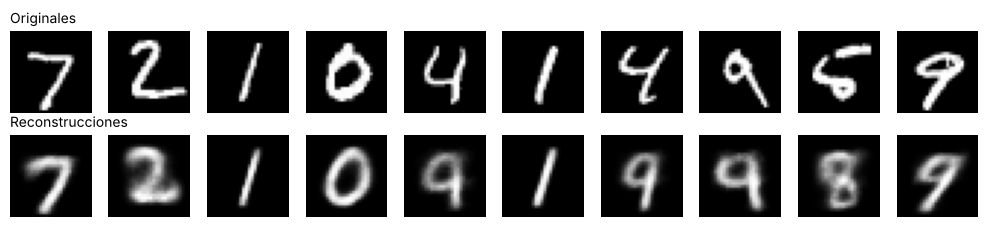

In [6]:
x, _ = next(iter(cargador_prueba))
x = x[:10].to(dispositivo)
with torch.no_grad():
    mu, _ = vae.encoder(x)
    reconstruccion = vae.decoder(mu)

fig, axs = plt.subplots(2, 10, figsize=(10, 2.3))
for i in range(10):
    axs[0, i].imshow(x[i, 0].cpu(), cmap="gray")
    axs[1, i].imshow(reconstruccion[i, 0].cpu(), cmap="gray")
    axs[0, i].axis("off")
    axs[1, i].axis("off")
axs[0, 0].set_title("Originales", loc="left", fontsize=10)
axs[1, 0].set_title("Reconstrucciones", loc="left", fontsize=10)
plt.tight_layout()
plt.show()

## El espacio latente

Como el espacio latente tiene dos dimensiones, cada imagen de prueba puede dibujarse como un punto (su media $\mu$), coloreado según el dígito que representa. El modelo nunca vio las etiquetas durante el entrenamiento; aun así, los dígitos se agrupan por clase. Además, los puntos se concentran alrededor del origen y ocupan una región compacta, efecto directo del término KL.

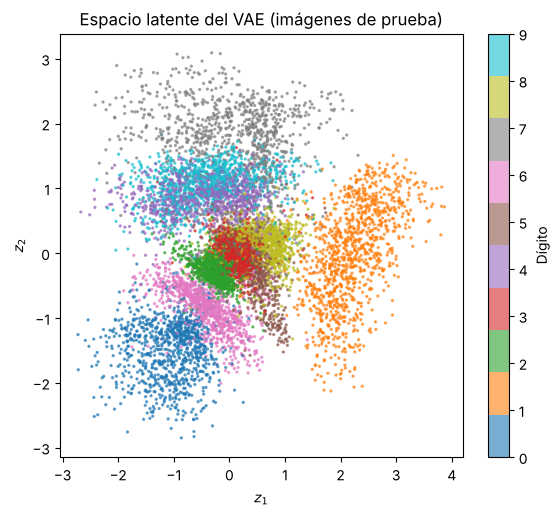

In [7]:
def codificar(modelo_codificador, cargador):
    codigos, etiquetas = [], []
    with torch.no_grad():
        for x, y in cargador:
            salida = modelo_codificador(x.to(dispositivo))
            codigos.append((salida[0] if isinstance(salida, tuple) else salida).cpu())
            etiquetas.append(y)
    return torch.cat(codigos).numpy(), torch.cat(etiquetas).numpy()


def dibujar_espacio_latente(ax, codigos, etiquetas, titulo):
    dispersion = ax.scatter(codigos[:, 0], codigos[:, 1], c=etiquetas, cmap="tab10", s=2, alpha=0.6)
    ax.set_xlabel("$z_1$")
    ax.set_ylabel("$z_2$")
    ax.set_title(titulo)
    return dispersion


codigos_vae, etiquetas = codificar(vae.encoder, cargador_prueba)
fig, ax = plt.subplots(figsize=(6.5, 5.5))
dispersion = dibujar_espacio_latente(ax, codigos_vae, etiquetas, "Espacio latente del VAE (imágenes de prueba)")
fig.colorbar(dispersion, ax=ax, ticks=range(10), label="Dígito")
plt.show()

## Recorrido del espacio latente

Ahora se hace el camino inverso: se recorre una cuadrícula de puntos del espacio latente y cada uno se decodifica en una imagen. Los puntos se eligen con los cuantiles de la normal estándar, de modo que cubran la región donde el modelo concentró los códigos. Las transiciones suaves entre dígitos vecinos muestran que el espacio es continuo: moverse un poco en el espacio latente cambia la imagen un poco.

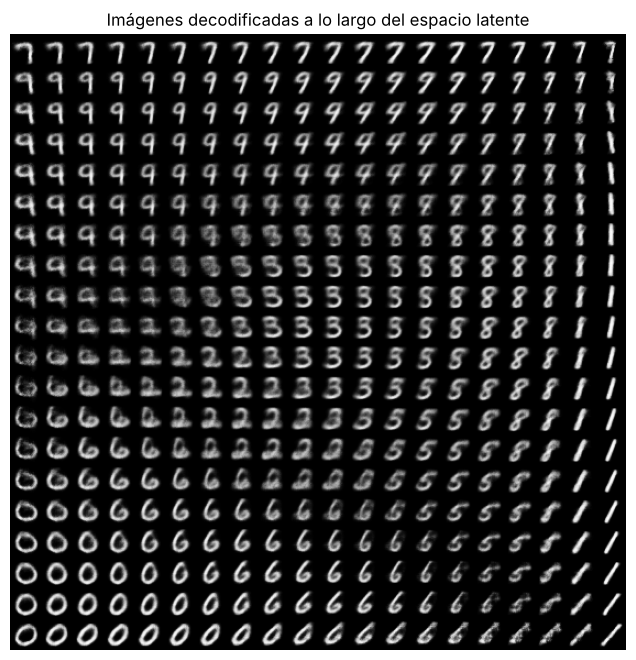

In [8]:
def mapa_latente(decodificador, n=20, limites=None):
    if limites is None:
        valores_1 = valores_2 = norm.ppf(np.linspace(0.03, 0.97, n))
    else:
        valores_1 = np.linspace(*limites[0], n)
        valores_2 = np.linspace(*limites[1], n)
    malla = np.array([[a, b] for b in valores_2[::-1] for a in valores_1], dtype=np.float32)
    with torch.no_grad():
        imagenes = decodificador(torch.from_numpy(malla).to(dispositivo)).cpu().numpy()
    return imagenes.reshape(n, n, 28, 28).transpose(0, 2, 1, 3).reshape(n * 28, n * 28)


plt.figure(figsize=(8, 8))
plt.imshow(mapa_latente(vae.decoder), cmap="gray")
plt.axis("off")
plt.title("Imágenes decodificadas a lo largo del espacio latente")
plt.show()

## Generación de imágenes nuevas

Gracias al término KL, se sabe de dónde muestrear: de una normal estándar. Basta tomar puntos $z \sim \mathcal{N}(0, I)$ y pasarlos por el decodificador; el codificador ya no interviene.

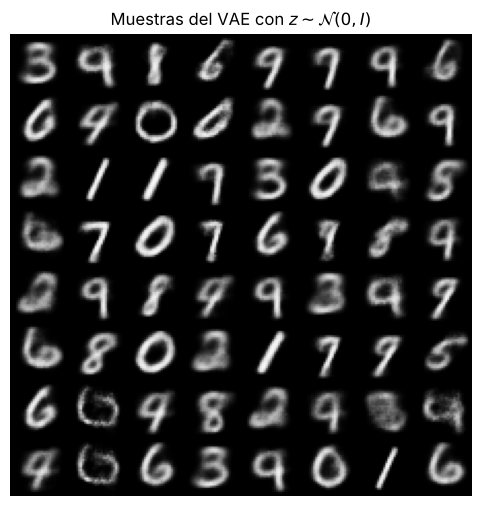

In [9]:
def generar(decodificador, z):
    with torch.no_grad():
        return decodificador(z.to(dispositivo)).cpu().numpy()[:, 0]


def dibujar_mosaico(ax, imagenes, columnas=8):
    filas = len(imagenes) // columnas
    mosaico = imagenes.reshape(filas, columnas, 28, 28).transpose(0, 2, 1, 3).reshape(filas * 28, columnas * 28)
    ax.imshow(mosaico, cmap="gray", vmin=0, vmax=1)
    ax.axis("off")


z_aleatorio = torch.randn(64, DIM_LATENTE)
fig, ax = plt.subplots(figsize=(6, 6))
dibujar_mosaico(ax, generar(vae.decoder, z_aleatorio))
ax.set_title("Muestras del VAE con $z \\sim \\mathcal{N}(0, I)$")
plt.show()

## Interpolación entre dos dígitos

Si se toman los códigos de dos imágenes reales y se recorre el segmento que los une, el decodificador produce una transición gradual de un dígito al otro. Cada imagen intermedia es plausible porque el espacio latente no tiene huecos entre ambas regiones.

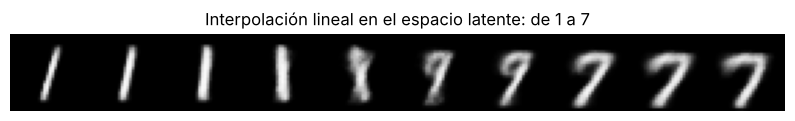

In [10]:
indice_a = int(np.where(etiquetas == 1)[0][0])
indice_b = int(np.where(etiquetas == 7)[0][0])
z_a = torch.from_numpy(codigos_vae[indice_a])
z_b = torch.from_numpy(codigos_vae[indice_b])

pasos = torch.linspace(0, 1, 10).unsqueeze(1)
z_interpolados = (1 - pasos) * z_a + pasos * z_b

fig, ax = plt.subplots(figsize=(10, 1.4))
dibujar_mosaico(ax, generar(vae.decoder, z_interpolados), columnas=10)
ax.set_title("Interpolación lineal en el espacio latente: de 1 a 7")
plt.show()

## Comparación con un autocodificador determinístico

Para ver qué aporta la parte variacional, se entrena un autocodificador con la misma arquitectura y el mismo espacio latente de dos dimensiones, pero sin muestreo ni término KL: el codificador produce directamente un punto y la pérdida es solo de reconstrucción. El entrenamiento tarda alrededor de un minuto con GPU.

In [11]:
class Autocodificador(nn.Module):
    def __init__(self, dim_latente=DIM_LATENTE):
        super().__init__()
        self.encoder = Codificador(dim_latente)  # solo se usa la salida de la media
        self.decoder = Decodificador(dim_latente)

    def codificar(self, x):
        return self.encoder(x)[0]

    def forward(self, x):
        return self.decoder(self.codificar(x))


torch.manual_seed(0)
autocodificador = Autocodificador().to(dispositivo)
optimizador = torch.optim.Adam(autocodificador.parameters(), lr=1e-3)

for epoca in range(1, 6):
    autocodificador.train()
    perdida_total = 0.0
    for x, _ in cargador_entrenamiento:
        x = x.to(dispositivo)
        perdida = F.binary_cross_entropy(autocodificador(x), x, reduction="sum")
        optimizador.zero_grad()
        perdida.backward()
        optimizador.step()
        perdida_total += perdida.item()
    print(f"Época {epoca} | pérdida de reconstrucción por imagen: {perdida_total / len(datos_entrenamiento):.1f}")
autocodificador.eval();

Época 1 | pérdida de reconstrucción por imagen: 179.7


Época 2 | pérdida de reconstrucción por imagen: 162.7


Época 3 | pérdida de reconstrucción por imagen: 157.9


Época 4 | pérdida de reconstrucción por imagen: 154.8


Época 5 | pérdida de reconstrucción por imagen: 152.7


Se comparan ambos espacios latentes. En el autocodificador, nada restringe la escala ni la forma de los códigos: las clases quedan en regiones alargadas, con huecos entre ellas y en una escala arbitraria. En el VAE, los códigos se concentran alrededor del origen con una forma aproximadamente circular, como lo exige el término KL.

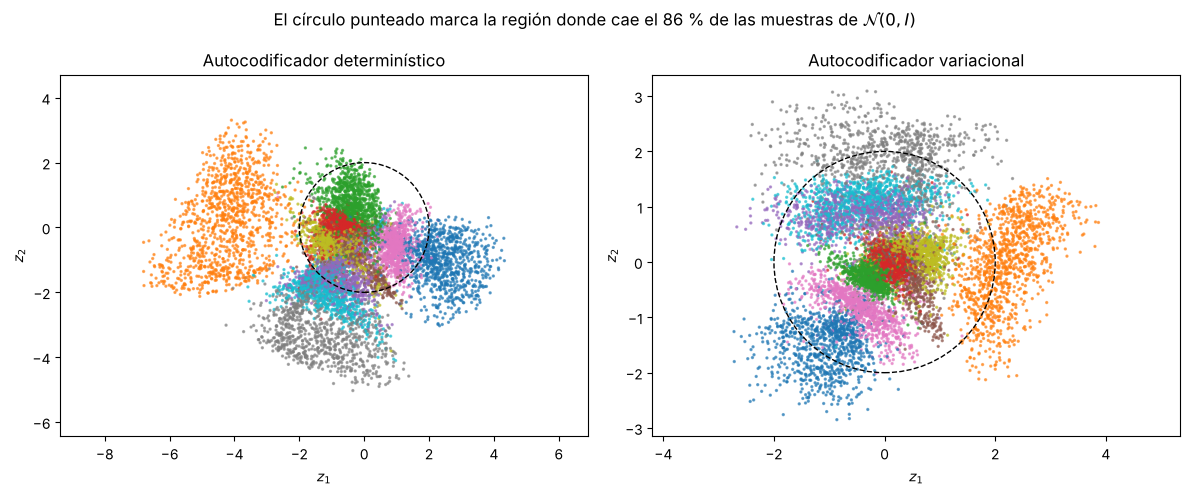

In [12]:
codigos_ae, _ = codificar(autocodificador.codificar, cargador_prueba)

fig, axs = plt.subplots(1, 2, figsize=(12, 5))
dibujar_espacio_latente(axs[0], codigos_ae, etiquetas, "Autocodificador determinístico")
dibujar_espacio_latente(axs[1], codigos_vae, etiquetas, "Autocodificador variacional")
for ax in axs:
    ax.add_patch(plt.Circle((0, 0), 2, fill=False, color="black", linestyle="--", linewidth=1))
    ax.set_aspect("equal", adjustable="datalim")
fig.suptitle("El círculo punteado marca la región donde cae el 86 % de las muestras de $\\mathcal{N}(0, I)$")
plt.tight_layout()
plt.show()

Finalmente, se generan imágenes con ambos modelos usando exactamente los mismos puntos aleatorios $z \sim \mathcal{N}(0, I)$. Para el VAE, esa es la distribución correcta. Para el autocodificador no existe una distribución conocida de la cual muestrear, así que parte de los puntos cae en regiones del espacio latente que el decodificador nunca vio durante el entrenamiento, y produce imágenes ambiguas o deformes; además, las muestras tienden a concentrarse en pocos dígitos, porque la región cercana al origen no está ocupada de forma equilibrada por todas las clases.

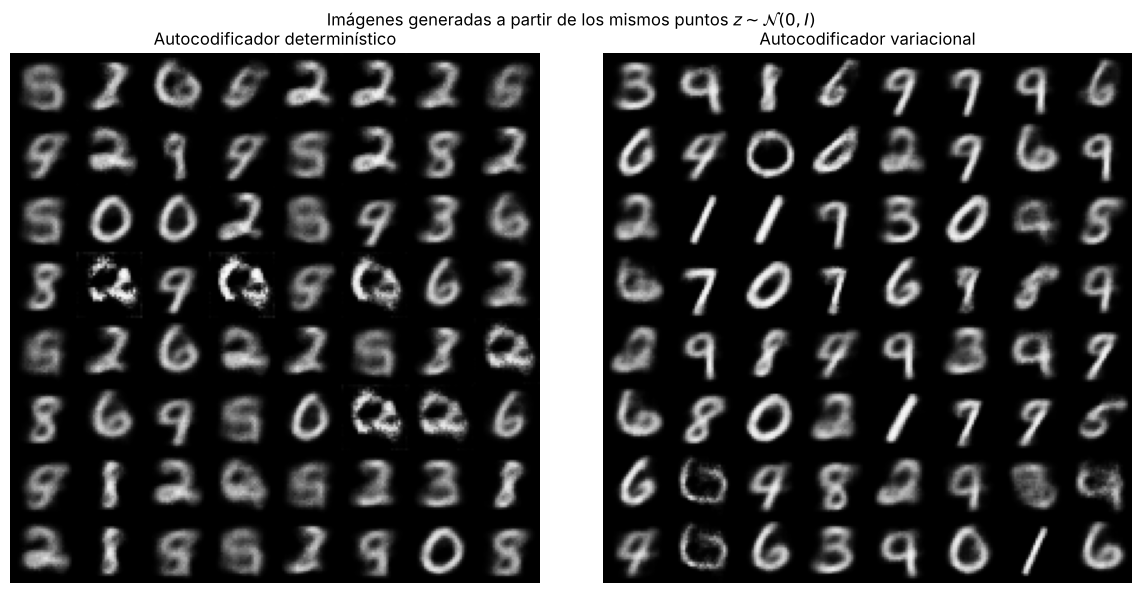

In [13]:
fig, axs = plt.subplots(1, 2, figsize=(12, 6))
dibujar_mosaico(axs[0], generar(autocodificador.decoder, z_aleatorio))
axs[0].set_title("Autocodificador determinístico")
dibujar_mosaico(axs[1], generar(vae.decoder, z_aleatorio))
axs[1].set_title("Autocodificador variacional")
fig.suptitle("Imágenes generadas a partir de los mismos puntos $z \\sim \\mathcal{N}(0, I)$")
plt.tight_layout()
plt.show()

## Conclusión

Ambos modelos comparten arquitectura y ambos reconstruyen razonablemente bien, pero solo el VAE es un modelo generativo útil. La diferencia está en la función de pérdida: el término KL organiza el espacio latente alrededor de una distribución conocida, de la cual se puede muestrear, y obliga a que ese espacio sea continuo. El costo es cierta borrosidad en las imágenes, porque el modelo promedia entre las posibilidades que caen en una misma región del espacio latente.